<a href="https://colab.research.google.com/github/monikaly13/TGI_Friday_Class/blob/main/assignment04_ASB2T4_LY_Monika_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(DEVICE)

cpu


In [ ]:
LR = 0.001
EPOCHS = 10
BATCH_SIZE = 64

train_set = datasets.FashionMNIST("data", train=True, download=True, transform=transforms.ToTensor())
test_set = datasets.FashionMNIST("data", train=False, download=True, transform=transforms.ToTensor())

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_set.classes
print(class_names)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.mlp(x)

In [ ]:
def train_loop(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        pred = model(images)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (pred.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

def eval_loop(model, loader, criterion):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            pred = model(images)
            total_loss += criterion(pred, labels).item()
            correct += (pred.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

In [ ]:
model = FashionMLP().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

train_losses, eval_losses, train_accs, eval_accs = [], [], [], []

for epoch in range(1, EPOCHS + 1):
    tl, ta = train_loop(model, train_loader, criterion, optimizer)
    el, ea = eval_loop(model, test_loader, criterion)
    train_losses.append(tl); train_accs.append(ta)
    eval_losses.append(el); eval_accs.append(ea)
    print(f"Epoch {epoch:02d}/{EPOCHS}  Train Loss={tl:.4f} Acc={ta:.4f}  Eval Loss={el:.4f} Acc={ea:.4f}")

torch.save(model.state_dict(), "fashion_mlp_ckpt.pth")
print("Saved checkpoint")

Epoch 01/10  Train Loss=0.5597 Acc=0.7978  Eval Loss=0.4263 Acc=0.8441
Epoch 02/10  Train Loss=0.4008 Acc=0.8548  Eval Loss=0.4038 Acc=0.8540
Epoch 03/10  Train Loss=0.3662 Acc=0.8670  Eval Loss=0.3670 Acc=0.8656
Epoch 04/10  Train Loss=0.3445 Acc=0.8734  Eval Loss=0.3839 Acc=0.8583
Epoch 05/10  Train Loss=0.3286 Acc=0.8801  Eval Loss=0.3636 Acc=0.8695
Epoch 06/10  Train Loss=0.3125 Acc=0.8851  Eval Loss=0.3417 Acc=0.8792
Epoch 07/10  Train Loss=0.3041 Acc=0.8877  Eval Loss=0.3323 Acc=0.8796
Epoch 08/10  Train Loss=0.2946 Acc=0.8898  Eval Loss=0.3318 Acc=0.8777
Epoch 09/10  Train Loss=0.2846 Acc=0.8938  Eval Loss=0.3439 Acc=0.8753
Epoch 10/10  Train Loss=0.2828 Acc=0.8946  Eval Loss=0.3192 Acc=0.8838
Saved checkpoint


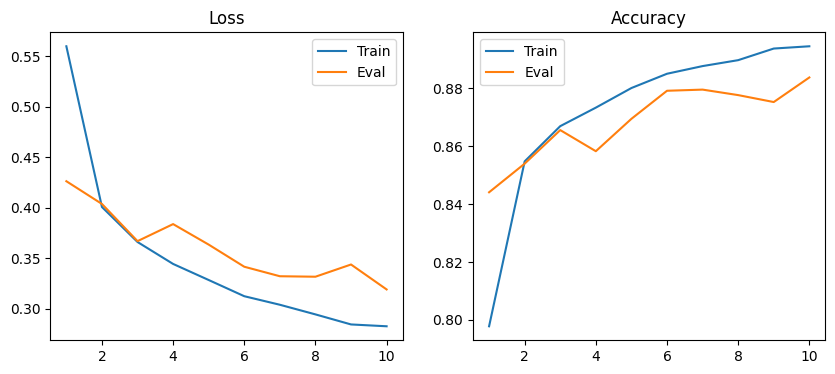

In [ ]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(epochs, train_losses, label="Train"); axes[0].plot(epochs, eval_losses, label="Eval")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(epochs, train_accs, label="Train"); axes[1].plot(epochs, eval_accs, label="Eval")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.show()

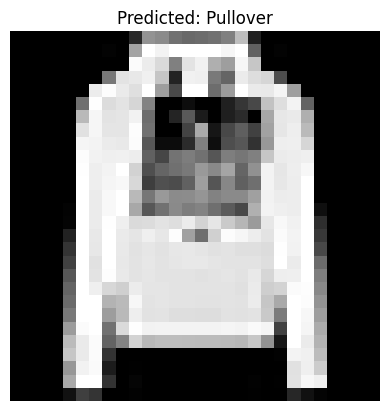

In [ ]:
loaded_model = FashionMLP().to(DEVICE)
loaded_model.load_state_dict(torch.load("fashion_mlp_ckpt.pth", map_location=DEVICE))
loaded_model.eval()

idx = random.randint(0, len(test_set) - 1)
image, true_label = test_set[idx]

with torch.no_grad():
    output = loaded_model(image.unsqueeze(0).to(DEVICE))
    pred_label = output.argmax(dim=1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Predicted: {class_names[pred_label]}")
plt.axis("off")
plt.show()